In [1]:
import pandas as pd
import glob
import os

In [2]:
# Tentukan folder tempat file CSV Anda berada (asumsi folder yang sama dengan Notebook)
FOLDER_PATH = './' 
OUTPUT_FILENAME = 'Performa_Rata_rata_Container.csv'

results_list = []
search_pattern = os.path.join(FOLDER_PATH, '*.csv')
all_files = glob.glob(search_pattern)

print(f"Ditemukan total {len(all_files)} file CSV untuk diproses.")

Ditemukan total 40 file CSV untuk diproses.


In [3]:
# --- Loop Pemrosesan Data ---
for filename in all_files:
    # Parsing Nama File untuk Label
    base_name = os.path.basename(filename).replace('.csv', '')
    parts = base_name.split('_')
    
    # Asumsi struktur: Container_Task_Model
    container = parts[0] 
    task = parts[1]      
    model = '_'.join(parts[2:])

    try:
        df = pd.read_csv(filename)
        # Menghitung Rata-rata dari 4 metrik
        avg_metrics = df[['cpu_usage_percent', 'processing_time_ms', 'ram_usage_mb', 'latency']].mean()
        
        result = {
            'Container': container.capitalize(),
            'Task': task.capitalize(),
            'Model': model,
            'Avg. Latency (ms)': round(avg_metrics['latency'], 2),
            'Avg. RAM Usage (MB)': round(avg_metrics['ram_usage_mb'], 2),
            'Avg. CPU (%)': round(avg_metrics['cpu_usage_percent'], 2),
            'Avg. Processing Time (ms)': round(avg_metrics['processing_time_ms'], 2)
        }
        results_list.append(result)
        
    except Exception as e:
        print(f"Error memproses file {filename}: {e}")
        continue

In [4]:
# 2. Membuat DataFrame Hasil Akhir
df_summary = pd.DataFrame(results_list)

In [ ]:
# 3. Menyimpan DataFrame ke File CSV Baru (Langkah Kunci)
df_summary.to_csv(OUTPUT_FILENAME, index=False)

print("\n--- Proses Selesai ---")
print(f"Rata-rata performa dari {len(df_summary)} data berhasil disimpan ke file: {OUTPUT_FILENAME}")


--- Proses Selesai ---
Rata-rata performa dari 40 data berhasil disimpan ke file: Performa_Rata_rata_Container.csv
Berikut adalah 5 baris pertama dari data ringkasan:


## PERBANDINGAN ANTAR CONTAINER

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from io import StringIO

In [ ]:
FILE_RATA_RATA = 'Performa_Rata_rata_Container.csv'

try:
    df_summary = pd.read_csv(FILE_RATA_RATA)
    print(f"File '{FILE_RATA_RATA}' berhasil dimuat. Total {len(df_summary)} baris data.")
except FileNotFoundError:
    print(f"ERROR: File '{FILE_RATA_RATA}' tidak ditemukan.")
    # Agar notebook tidak berhenti, Anda mungkin ingin mengganti exit() dengan pass atau raise error
    raise FileNotFoundError(f"File '{FILE_RATA_RATA}' tidak ditemukan.")

# --- MEMISAHKAN DATA BERDASARKAN TASK (Penting untuk strategi baru) ---
df_classification = df_summary[df_summary['Task'] == 'Classification'].copy()
df_segmentation = df_summary[df_summary['Task'] == 'Segmentation'].copy()

print(f"Data Klasifikasi Siap: {len(df_classification)} baris")
print(f"Data Segmentasi Siap: {len(df_segmentation)} baris")

# Daftar metrik untuk mempermudah penulisan Cell 2 dan seterusnya
metrics = {
    'Avg. Latency (ms)': ('ms', 'Pastel1'),
    'Avg. RAM Usage (MB)': ('MB', 'Accent'),
    'Avg. CPU (%)': ('%', 'Set1'),
    'Avg. Processing Time (ms)': ('ms', 'viridis')
}

File 'Performa_Rata_rata_Container.csv' berhasil dimuat. Total 40 baris data.
Data Klasifikasi Siap: 20 baris
Data Segmentasi Siap: 20 baris


## VISUALISASI PARAMETER PADA KLASIFIKASI

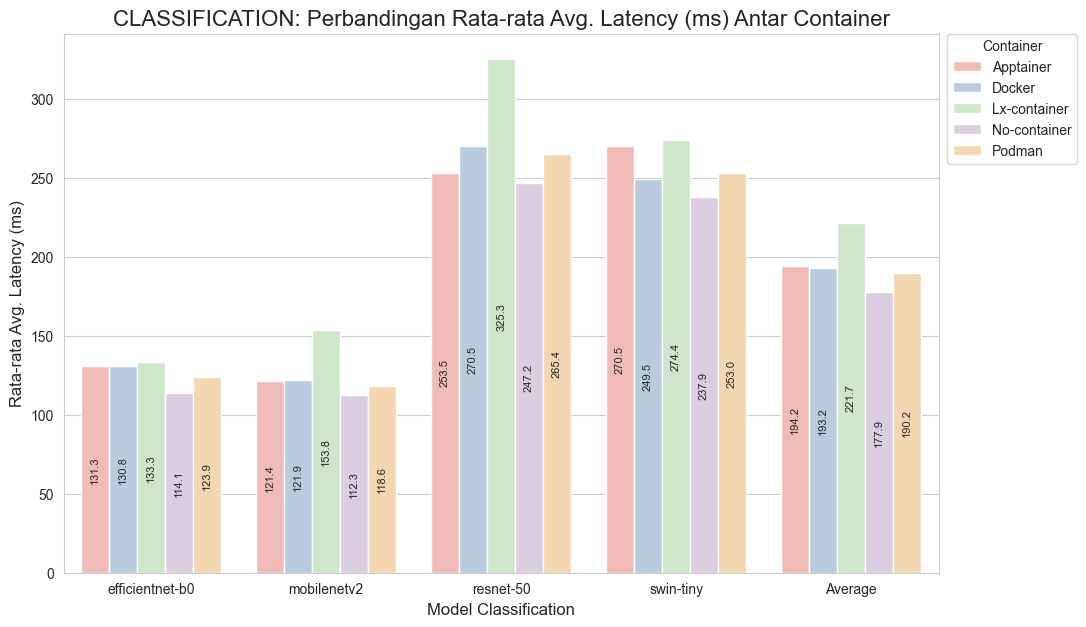

In [ ]:
TASK = 'Classification'               # 'Classification' atau 'Segmentation'
METRIC = 'Avg. Latency (ms)'          # Metrik yang ingin divisualisasikan
PALETTE = 'Pastel1'                   # Palet warna

# --- Persiapan Data ---
UNIT = 'ms'
if METRIC == 'Avg. RAM Usage (MB)': UNIT = 'MB'
if METRIC == 'Avg. CPU (%)': UNIT = '%'

# Pastikan Anda sudah menjalankan Cell 1 yang memuat df_classification dan df_segmentation
df_task = df_classification if TASK == 'Classification' else df_segmentation

# --- Tambahkan kolom "Average" per container ---
df_avg = (
    df_task
    .groupby('Container', as_index=False)[METRIC]
    .mean()
)
df_avg['Model'] = 'Average'  # Kolom baru dengan label rata-rata
df_task_plot = pd.concat([df_task, df_avg], ignore_index=True)

# --- MEMBUAT GRAFIK ---
plt.figure(figsize=(14, 7))
sns.set_style("whitegrid")

ax = sns.barplot(
    x='Model',
    y=METRIC,
    hue='Container',
    data=df_task_plot,
    palette=PALETTE
)

plt.title(f'{TASK.upper()}: Perbandingan Rata-rata {METRIC} Antar Container', fontsize=16)
plt.xlabel(f'Model {TASK}', fontsize=12)
plt.ylabel(f'Rata-rata {METRIC}', fontsize=12)

# Rotasi label hanya jika task segmentation (biasanya banyak model panjang)
plt.xticks(rotation=45 if TASK == 'Segmentation' else 0,
           ha='right' if TASK == 'Segmentation' else 'center')

# --- MEMINDAHKAN LEGEND ---
plt.legend(
    title='Container',
    loc='upper left',
    bbox_to_anchor=(1.01, 1.0),
    borderaxespad=0.
)

# --- MENAMBAH NILAI DATA (LABEL DI ATAS BAR) ---
for p in ax.patches:
    height = p.get_height()

    if METRIC == 'Avg. CPU (%)':
        label = f'{height:.2f}%'
    elif height > 5000:
        label = f'{height/1000:.1f}s'
    elif height < 100:
        label = f'{height:.2f}'
    else:
        label = f'{height:.1f}'

    y_position = height *0.50

    if height > 0.01:
        ax.annotate(
            label, 
            (p.get_x() + p.get_width() / 2., y_position),
            ha = 'center', 
            va = 'center', 
            xytext = (0, 0),
            rotation=90, 
            textcoords = 'offset points',
            fontsize=8
    )

# --- TAMBAHKAN RUANG UNTUK LEGEND ---
plt.subplots_adjust(right=0.75)
plt.show()


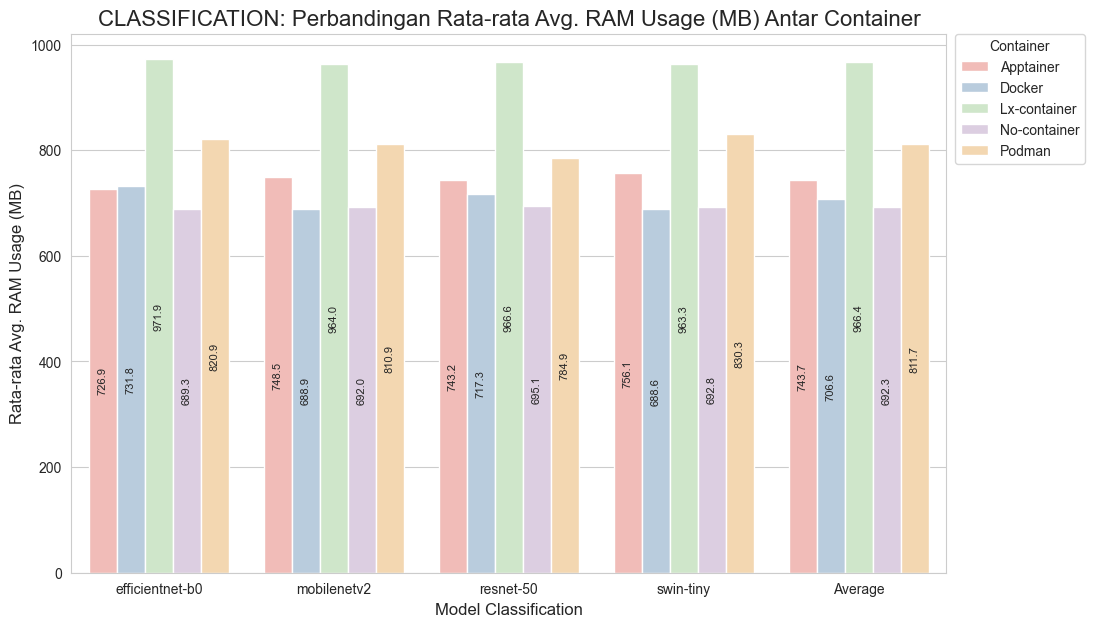

In [ ]:
TASK = 'Classification'               # 'Classification' atau 'Segmentation'
METRIC = 'Avg. RAM Usage (MB)'          # Metrik yang ingin divisualisasikan
PALETTE = 'Pastel1'                   # Palet warna

# --- Persiapan Data (Hampir sama dengan sebelumnya) ---
UNIT = 'ms' # Sesuaikan unit secara manual berdasarkan METRIC
if METRIC == 'Avg. RAM Usage (MB)': UNIT = 'MB'
if METRIC == 'Avg. CPU (%)': UNIT = '%'
# Pastikan Anda sudah menjalankan Cell 1 yang memuat df_classification dan df_segmentation
df_task = df_classification if TASK == 'Classification' else df_segmentation

# --- Tambahkan kolom "Average" per container ---
df_avg = (
    df_task
    .groupby('Container', as_index=False)[METRIC]
    .mean()
)
df_avg['Model'] = 'Average'  # Kolom baru dengan label rata-rata
df_task_plot = pd.concat([df_task, df_avg], ignore_index=True)

# --- MEMBUAT GRAFIK ---
plt.figure(figsize=(14, 7)) # Sedikit perbesar lebar figure untuk ruang
sns.set_style("whitegrid")

ax = sns.barplot(x='Model', y=METRIC, hue='Container', data=df_task_plot, palette=PALETTE)

plt.title(f'{TASK.upper()}: Perbandingan Rata-rata {METRIC} Antar Container', fontsize=16)
plt.xlabel(f'Model {TASK}', fontsize=12)
plt.ylabel(f'Rata-rata {METRIC}', fontsize=12)
plt.xticks(rotation=45 if TASK == 'Segmentation' else 0, ha='right' if TASK == 'Segmentation' else 'center')

# --- PERBAIKAN: MEMINDAHKAN LEGEND ---
# Legenda dipindahkan ke kanan luar area plot (bbox_to_anchor=(1.05, 1))
plt.legend(
    title='Container', 
    loc='upper left', 
    bbox_to_anchor=(1.01, 1.0), # Pindah ke kanan luar
    borderaxespad=0.
)

# --- MENAMBAH NILAI DATA (DATA LABEL) ---
for p in ax.patches:
    height = p.get_height()
    
    # ... (Logic untuk format label) ...
    if METRIC == 'Avg. CPU (%)':
        label = f'{height:.2f}%'
    elif height > 5000:
        label = f'{height/1000:.1f}s' 
    elif height < 100:
        label = f'{height:.2f}'
    else:
        label = f'{height:.1f}'

    y_position = height *0.50

    if height > 0.01:
        ax.annotate(
            label, 
            (p.get_x() + p.get_width() / 2., y_position),
            ha = 'center', 
            va = 'center', 
            xytext = (0, 0),
            rotation=90, 
            textcoords = 'offset points',
            fontsize=8
    )

# --- PENYESUAIAN TAMBAHAN (MEMBERI RUANG) ---
# Tambahkan padding di bagian kanan untuk memberi ruang legenda
plt.subplots_adjust(right=0.75) 
plt.show()

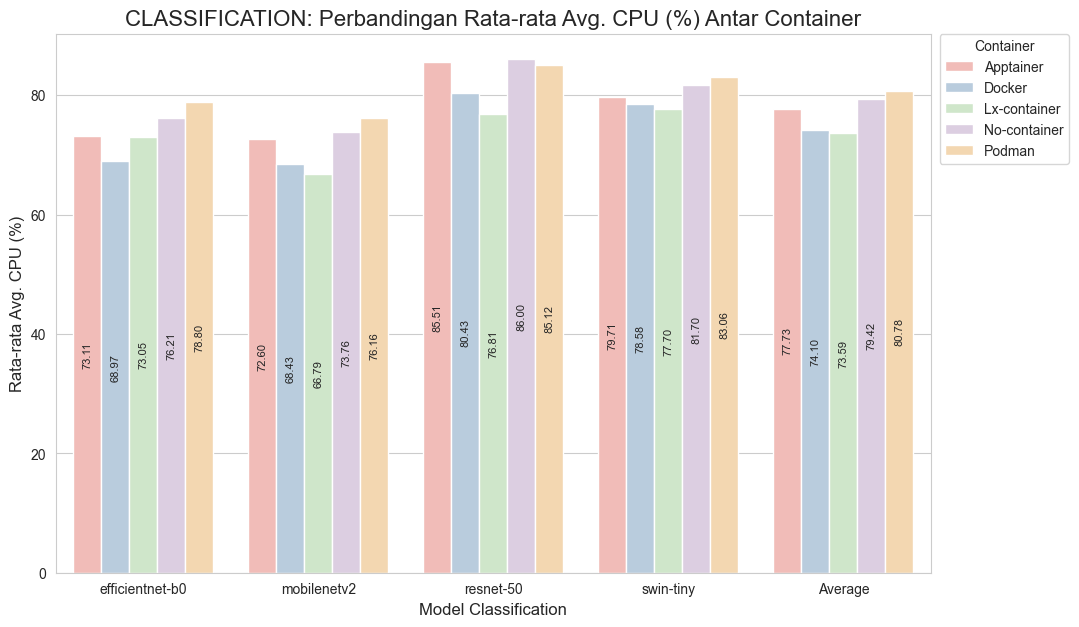

In [5]:
TASK = 'Classification'               # 'Classification' atau 'Segmentation'
METRIC = 'Avg. CPU (%)'          # Metrik yang ingin divisualisasikan
PALETTE = 'Pastel1'                   # Palet warna

# --- Persiapan Data (Hampir sama dengan sebelumnya) ---
UNIT = 'ms' # Sesuaikan unit secara manual berdasarkan METRIC
if METRIC == 'Avg. RAM Usage (MB)': UNIT = 'MB'
if METRIC == 'Avg. CPU (%)': UNIT = '%'
# Pastikan Anda sudah menjalankan Cell 1 yang memuat df_classification dan df_segmentation
df_task = df_classification if TASK == 'Classification' else df_segmentation

# --- Tambahkan kolom "Average" per container ---
df_avg = (
    df_task
    .groupby('Container', as_index=False)[METRIC]
    .mean()
)
df_avg['Model'] = 'Average'  # Kolom baru dengan label rata-rata
df_task_plot = pd.concat([df_task, df_avg], ignore_index=True)

# --- MEMBUAT GRAFIK ---
plt.figure(figsize=(14, 7)) # Sedikit perbesar lebar figure untuk ruang
sns.set_style("whitegrid")

ax = sns.barplot(x='Model', y=METRIC, hue='Container', data=df_task_plot, palette=PALETTE)

plt.title(f'{TASK.upper()}: Perbandingan Rata-rata {METRIC} Antar Container', fontsize=16)
plt.xlabel(f'Model {TASK}', fontsize=12)
plt.ylabel(f'Rata-rata {METRIC}', fontsize=12)
plt.xticks(rotation=45 if TASK == 'Segmentation' else 0, ha='right' if TASK == 'Segmentation' else 'center')

# --- PERBAIKAN: MEMINDAHKAN LEGEND ---
# Legenda dipindahkan ke kanan luar area plot (bbox_to_anchor=(1.05, 1))
plt.legend(
    title='Container', 
    loc='upper left', 
    bbox_to_anchor=(1.01, 1.0), # Pindah ke kanan luar
    borderaxespad=0.
)

# --- MENAMBAH NILAI DATA (DATA LABEL) ---
for p in ax.patches:
    height = p.get_height()
    
    # ... (Logic untuk format label) ...
    if METRIC == 'Avg. CPU (%)':
        label = f'{height:.2f}'
    elif height > 5000:
        label = f'{height/1000:.1f}s' 
    elif height < 100:
        label = f'{height:.2f}'
    else:
        label = f'{height:.1f}'

    y_position = height *0.50

    if height > 0.01:
        ax.annotate(
            label, 
            (p.get_x() + p.get_width() / 2., y_position),
            ha = 'center', 
            va = 'center', 
            xytext = (0, 0),
            rotation=90, 
            textcoords = 'offset points',
            fontsize=8
    )

# --- PENYESUAIAN TAMBAHAN (MEMBERI RUANG) ---
# Tambahkan padding di bagian kanan untuk memberi ruang legenda
plt.subplots_adjust(right=0.75) 
plt.show()

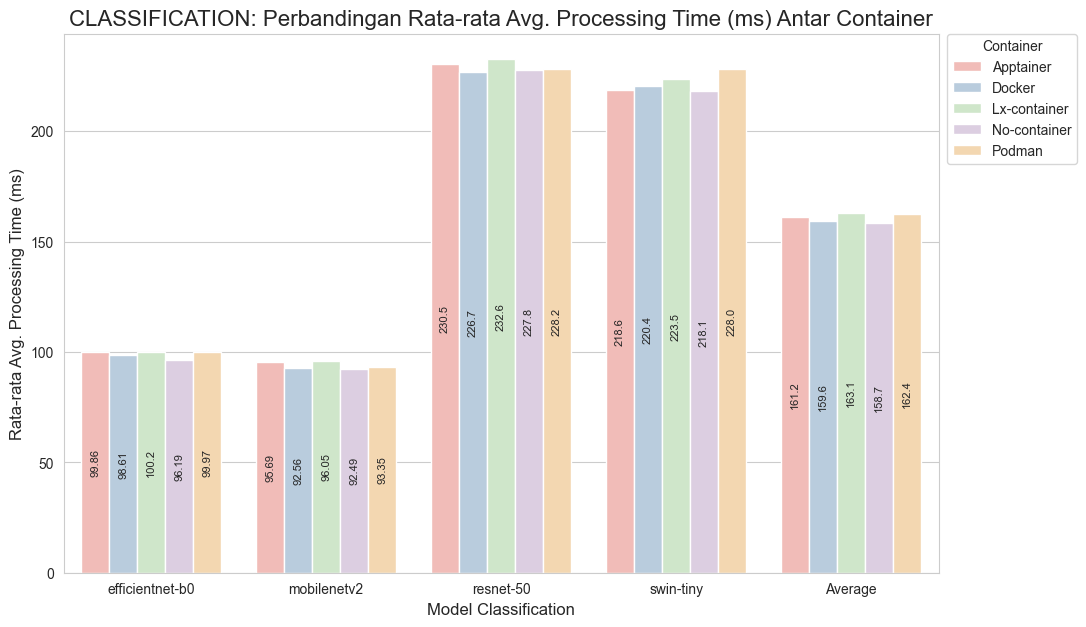

In [6]:
TASK = 'Classification'               # 'Classification' atau 'Segmentation'
METRIC = 'Avg. Processing Time (ms)'          # Metrik yang ingin divisualisasikan
PALETTE = 'Pastel1'                   # Palet warna

# --- Persiapan Data (Hampir sama dengan sebelumnya) ---
UNIT = 'ms' # Sesuaikan unit secara manual berdasarkan METRIC
if METRIC == 'Avg. RAM Usage (MB)': UNIT = 'MB'
if METRIC == 'Avg. CPU (%)': UNIT = '%'
# Pastikan Anda sudah menjalankan Cell 1 yang memuat df_classification dan df_segmentation
df_task = df_classification if TASK == 'Classification' else df_segmentation

# --- Tambahkan kolom "Average" per container ---
df_avg = (
    df_task
    .groupby('Container', as_index=False)[METRIC]
    .mean()
)
df_avg['Model'] = 'Average'  # Kolom baru dengan label rata-rata
df_task_plot = pd.concat([df_task, df_avg], ignore_index=True)

# --- MEMBUAT GRAFIK ---
plt.figure(figsize=(14, 7)) # Sedikit perbesar lebar figure untuk ruang
sns.set_style("whitegrid")

ax = sns.barplot(x='Model', y=METRIC, hue='Container', data=df_task_plot, palette=PALETTE)

plt.title(f'{TASK.upper()}: Perbandingan Rata-rata {METRIC} Antar Container', fontsize=16)
plt.xlabel(f'Model {TASK}', fontsize=12)
plt.ylabel(f'Rata-rata {METRIC}', fontsize=12)
plt.xticks(rotation=45 if TASK == 'Segmentation' else 0, ha='right' if TASK == 'Segmentation' else 'center')

# --- PERBAIKAN: MEMINDAHKAN LEGEND ---
# Legenda dipindahkan ke kanan luar area plot (bbox_to_anchor=(1.05, 1))
plt.legend(
    title='Container', 
    loc='upper left', 
    bbox_to_anchor=(1.01, 1.0), # Pindah ke kanan luar
    borderaxespad=0.
)

# --- MENAMBAH NILAI DATA (DATA LABEL) ---
for p in ax.patches:
    height = p.get_height()
    
    # ... (Logic untuk format label) ...
    if METRIC == 'Avg. CPU (%)':
        label = f'{height:.2f}%'
    elif height > 5000:
        label = f'{height/1000:.1f}s' 
    elif height < 100:
        label = f'{height:.2f}'
    else:
        label = f'{height:.1f}'

    y_position = height *0.50

    if height > 0.01:
        ax.annotate(
            label, 
            (p.get_x() + p.get_width() / 2., y_position),
            ha = 'center', 
            va = 'center', 
            xytext = (0, 0),
            rotation=90, 
            textcoords = 'offset points',
            fontsize=8
    )
# --- PENYESUAIAN TAMBAHAN (MEMBERI RUANG) ---
# Tambahkan padding di bagian kanan untuk memberi ruang legenda
plt.subplots_adjust(right=0.75) 
plt.show() 

## VISUALISASI PARAMETER PADA SEGMENTASI

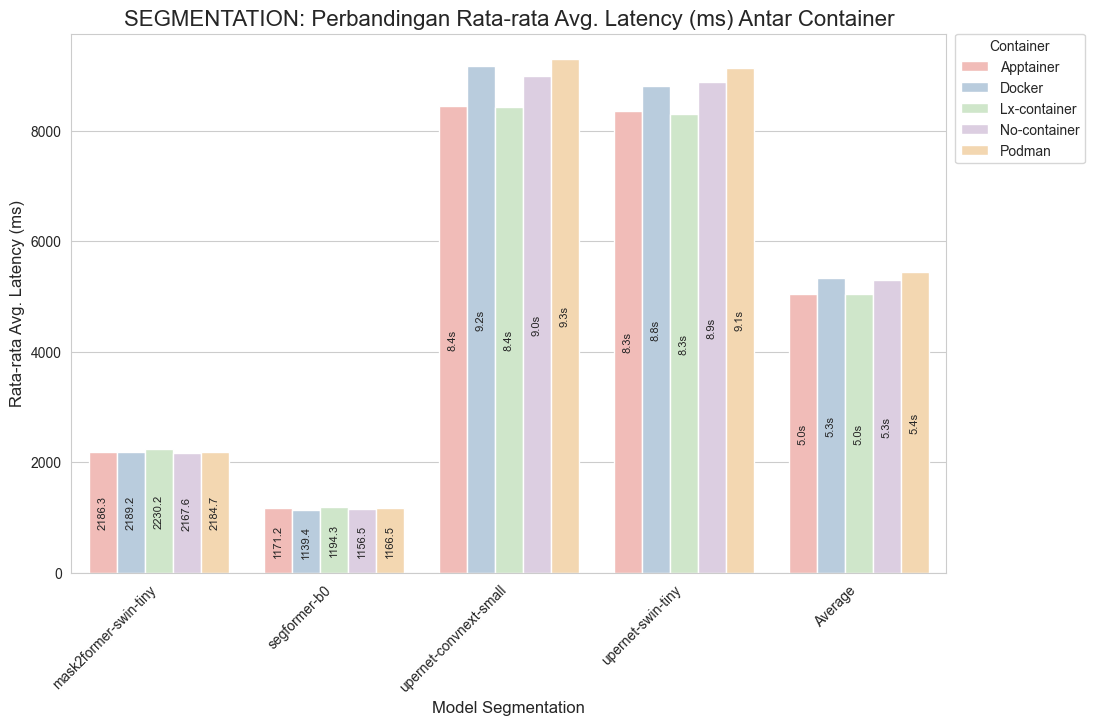

In [7]:
TASK = 'Segmentation'               # 'Classification' atau 'Segmentation'
METRIC = 'Avg. Latency (ms)'          # Metrik yang ingin divisualisasikan
PALETTE = 'Pastel1'                   # Palet warna

# --- Persiapan Data (Hampir sama dengan sebelumnya) ---
UNIT = 'ms' # Sesuaikan unit secara manual berdasarkan METRIC
if METRIC == 'Avg. RAM Usage (MB)': UNIT = 'MB'
if METRIC == 'Avg. CPU (%)': UNIT = '%'
# Pastikan Anda sudah menjalankan Cell 1 yang memuat df_classification dan df_segmentation
df_task = df_classification if TASK == 'Classification' else df_segmentation

# --- Tambahkan kolom "Average" per container ---
df_avg = (
    df_task
    .groupby('Container', as_index=False)[METRIC]
    .mean()
)
df_avg['Model'] = 'Average'  # Kolom baru dengan label rata-rata
df_task_plot = pd.concat([df_task, df_avg], ignore_index=True)

# --- MEMBUAT GRAFIK ---
plt.figure(figsize=(14, 7)) # Sedikit perbesar lebar figure untuk ruang
sns.set_style("whitegrid")

ax = sns.barplot(x='Model', y=METRIC, hue='Container', data=df_task_plot, palette=PALETTE)

plt.title(f'{TASK.upper()}: Perbandingan Rata-rata {METRIC} Antar Container', fontsize=16)
plt.xlabel(f'Model {TASK}', fontsize=12)
plt.ylabel(f'Rata-rata {METRIC}', fontsize=12)
plt.xticks(rotation=45 if TASK == 'Segmentation' else 0, ha='right' if TASK == 'Segmentation' else 'center')

# --- PERBAIKAN: MEMINDAHKAN LEGEND ---
# Legenda dipindahkan ke kanan luar area plot (bbox_to_anchor=(1.05, 1))
plt.legend(
    title='Container', 
    loc='upper left', 
    bbox_to_anchor=(1.01, 1.0), # Pindah ke kanan luar
    borderaxespad=0.
)

# --- MENAMBAH NILAI DATA (DATA LABEL) ---
for p in ax.patches:
    height = p.get_height()
    
    # ... (Logic untuk format label) ...
    if METRIC == 'Avg. CPU (%)':
        label = f'{height:.2f}%'
    elif height > 5000:
        label = f'{height/1000:.1f}s' 
    elif height < 100:
        label = f'{height:.2f}'
    else:
        label = f'{height:.1f}'
    
    y_position = height *0.50

    if height > 0.01:
        ax.annotate(
            label, 
            (p.get_x() + p.get_width() / 2., y_position),
            ha = 'center', 
            va = 'center', 
            xytext = (0, 0),
            rotation=90, 
            textcoords = 'offset points',
            fontsize=8
    )

# --- PENYESUAIAN TAMBAHAN (MEMBERI RUANG) ---
# Tambahkan padding di bagian kanan untuk memberi ruang legenda
plt.subplots_adjust(right=0.75) 
plt.show()

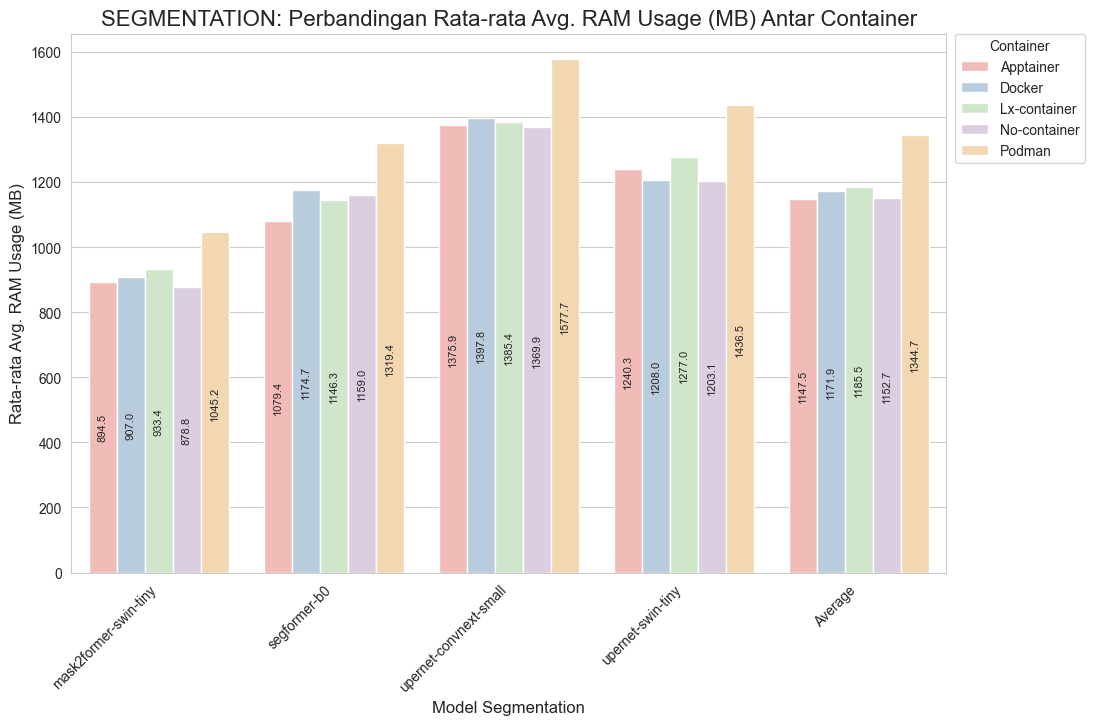

In [8]:
TASK = 'Segmentation'               # 'Classification' atau 'Segmentation'
METRIC = 'Avg. RAM Usage (MB)'          # Metrik yang ingin divisualisasikan
PALETTE = 'Pastel1'                   # Palet warna

# --- Persiapan Data (Hampir sama dengan sebelumnya) ---
UNIT = 'ms' # Sesuaikan unit secara manual berdasarkan METRIC
if METRIC == 'Avg. RAM Usage (MB)': UNIT = 'MB'
if METRIC == 'Avg. CPU (%)': UNIT = '%'
# Pastikan Anda sudah menjalankan Cell 1 yang memuat df_classification dan df_segmentation
df_task = df_classification if TASK == 'Classification' else df_segmentation

# --- Tambahkan kolom "Average" per container ---
df_avg = (
    df_task
    .groupby('Container', as_index=False)[METRIC]
    .mean()
)
df_avg['Model'] = 'Average'  # Kolom baru dengan label rata-rata
df_task_plot = pd.concat([df_task, df_avg], ignore_index=True)

# --- MEMBUAT GRAFIK ---
plt.figure(figsize=(14, 7)) # Sedikit perbesar lebar figure untuk ruang
sns.set_style("whitegrid")

ax = sns.barplot(x='Model', y=METRIC, hue='Container', data=df_task_plot, palette=PALETTE)

plt.title(f'{TASK.upper()}: Perbandingan Rata-rata {METRIC} Antar Container', fontsize=16)
plt.xlabel(f'Model {TASK}', fontsize=12)
plt.ylabel(f'Rata-rata {METRIC}', fontsize=12)
plt.xticks(rotation=45 if TASK == 'Segmentation' else 0, ha='right' if TASK == 'Segmentation' else 'center')

# --- PERBAIKAN: MEMINDAHKAN LEGEND ---
# Legenda dipindahkan ke kanan luar area plot (bbox_to_anchor=(1.05, 1))
plt.legend(
    title='Container', 
    loc='upper left', 
    bbox_to_anchor=(1.01, 1.0), # Pindah ke kanan luar
    borderaxespad=0.
)

# --- MENAMBAH NILAI DATA (DATA LABEL) ---
for p in ax.patches:
    height = p.get_height()
    
    # ... (Logic untuk format label) ...
    if METRIC == 'Avg. CPU (%)':
        label = f'{height:.2f}%'
    elif height > 5000:
        label = f'{height/1000:.1f}s' 
    elif height < 100:
        label = f'{height:.2f}'
    else:
        label = f'{height:.1f}'

    y_position = height *0.50

    if height > 0.01:
        ax.annotate(
            label, 
            (p.get_x() + p.get_width() / 2., y_position),
            ha = 'center', 
            va = 'center', 
            xytext = (0, 0),
            rotation=90, 
            textcoords = 'offset points',
            fontsize=8
    )

# --- PENYESUAIAN TAMBAHAN (MEMBERI RUANG) ---
# Tambahkan padding di bagian kanan untuk memberi ruang legenda
plt.subplots_adjust(right=0.75) 
plt.show()

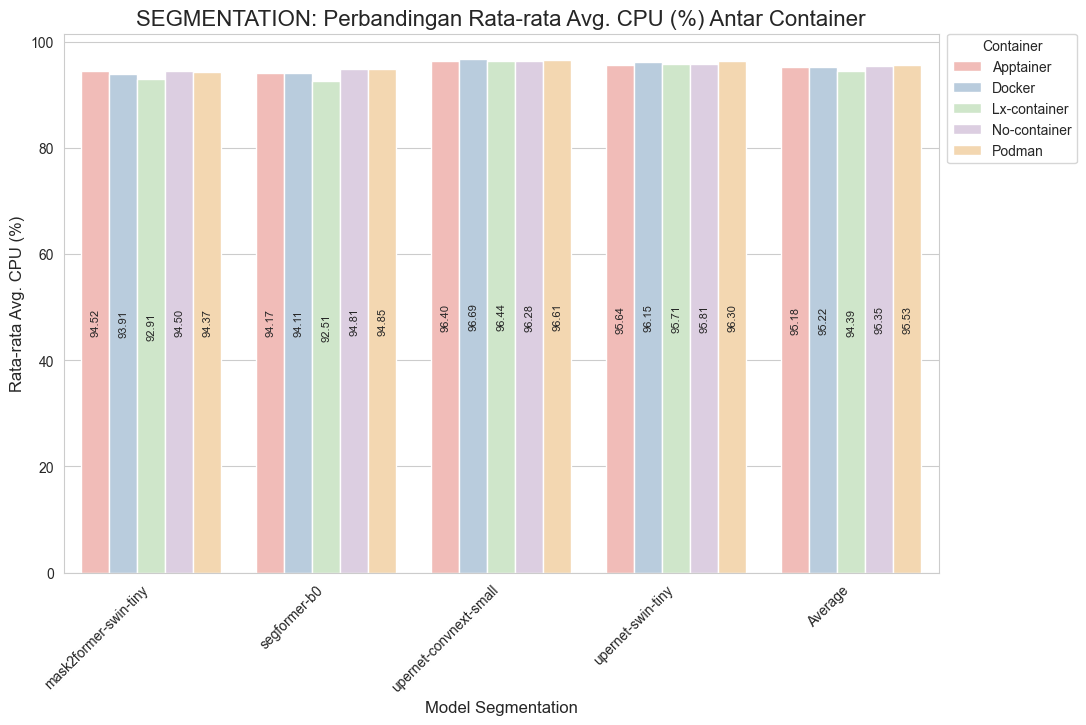

In [9]:
TASK = 'Segmentation'               # 'Classification' atau 'Segmentation'
METRIC = 'Avg. CPU (%)'          # Metrik yang ingin divisualisasikan
PALETTE = 'Pastel1'                   # Palet warna

# --- Persiapan Data (Hampir sama dengan sebelumnya) ---
UNIT = 'ms' # Sesuaikan unit secara manual berdasarkan METRIC
if METRIC == 'Avg. RAM Usage (MB)': UNIT = 'MB'
if METRIC == 'Avg. CPU (%)': UNIT = '%'
# Pastikan Anda sudah menjalankan Cell 1 yang memuat df_classification dan df_segmentation
df_task = df_classification if TASK == 'Classification' else df_segmentation

# --- Tambahkan kolom "Average" per container ---
df_avg = (
    df_task
    .groupby('Container', as_index=False)[METRIC]
    .mean()
)
df_avg['Model'] = 'Average'  # Kolom baru dengan label rata-rata
df_task_plot = pd.concat([df_task, df_avg], ignore_index=True)

# --- MEMBUAT GRAFIK ---
plt.figure(figsize=(14, 7)) # Sedikit perbesar lebar figure untuk ruang
sns.set_style("whitegrid")

ax = sns.barplot(x='Model', y=METRIC, hue='Container', data=df_task_plot, palette=PALETTE)

plt.title(f'{TASK.upper()}: Perbandingan Rata-rata {METRIC} Antar Container', fontsize=16)
plt.xlabel(f'Model {TASK}', fontsize=12)
plt.ylabel(f'Rata-rata {METRIC}', fontsize=12)
plt.xticks(rotation=45 if TASK == 'Segmentation' else 0, ha='right' if TASK == 'Segmentation' else 'center')

# --- PERBAIKAN: MEMINDAHKAN LEGEND ---
# Legenda dipindahkan ke kanan luar area plot (bbox_to_anchor=(1.05, 1))
plt.legend(
    title='Container', 
    loc='upper left', 
    bbox_to_anchor=(1.01, 1.0), # Pindah ke kanan luar
    borderaxespad=0.
)

# --- MENAMBAH NILAI DATA (DATA LABEL) ---
for p in ax.patches:
    height = p.get_height()
    
    # ... (Logic untuk format label) ...
    if METRIC == 'Avg. CPU (%)':
        label = f'{height:.2f}'
    elif height > 5000:
        label = f'{height/1000:.1f}s' 
    elif height < 100:
        label = f'{height:.2f}'
    else:
        label = f'{height:.1f}'

    y_position = height *0.50

    if height > 0.01:
        ax.annotate(
            label, 
            (p.get_x() + p.get_width() / 2., y_position),
            ha = 'center', 
            va = 'center', 
            xytext = (0, 0),
            rotation=90, 
            textcoords = 'offset points',
            fontsize=8
    )

# --- PENYESUAIAN TAMBAHAN (MEMBERI RUANG) ---
# Tambahkan padding di bagian kanan untuk memberi ruang legenda
plt.subplots_adjust(right=0.75) 
plt.show()

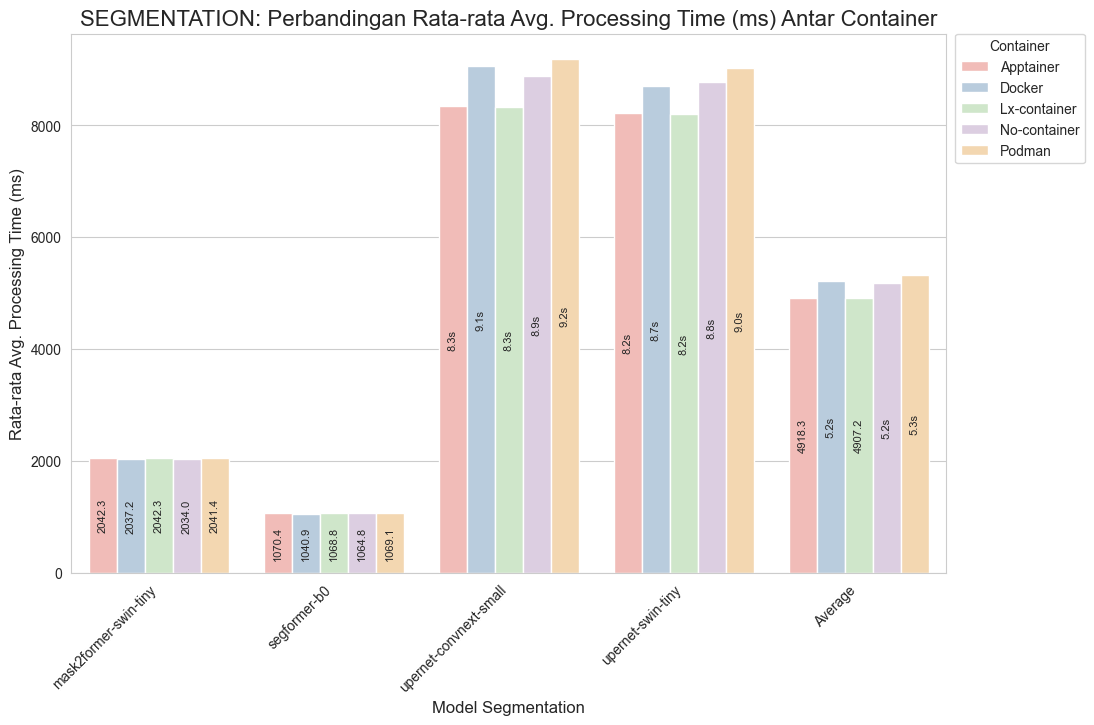

In [10]:
TASK = 'Segmentation'               # 'Classification' atau 'Segmentation'
METRIC = 'Avg. Processing Time (ms)'          # Metrik yang ingin divisualisasikan
PALETTE = 'Pastel1'                   # Palet warna

# --- Persiapan Data (Hampir sama dengan sebelumnya) ---
UNIT = 'ms' # Sesuaikan unit secara manual berdasarkan METRIC
if METRIC == 'Avg. RAM Usage (MB)': UNIT = 'MB'
if METRIC == 'Avg. CPU (%)': UNIT = '%'
# Pastikan Anda sudah menjalankan Cell 1 yang memuat df_classification dan df_segmentation
df_task = df_classification if TASK == 'Classification' else df_segmentation

# --- Tambahkan kolom "Average" per container ---
df_avg = (
    df_task
    .groupby('Container', as_index=False)[METRIC]
    .mean()
)
df_avg['Model'] = 'Average'  # Kolom baru dengan label rata-rata
df_task_plot = pd.concat([df_task, df_avg], ignore_index=True)
# --- MEMBUAT GRAFIK ---
plt.figure(figsize=(14, 7)) # Sedikit perbesar lebar figure untuk ruang
sns.set_style("whitegrid")

ax = sns.barplot(x='Model', y=METRIC, hue='Container', data=df_task_plot, palette=PALETTE)

plt.title(f'{TASK.upper()}: Perbandingan Rata-rata {METRIC} Antar Container', fontsize=16)
plt.xlabel(f'Model {TASK}', fontsize=12)
plt.ylabel(f'Rata-rata {METRIC}', fontsize=12)
plt.xticks(rotation=45 if TASK == 'Segmentation' else 0, ha='right' if TASK == 'Segmentation' else 'center')

# --- PERBAIKAN: MEMINDAHKAN LEGEND ---
# Legenda dipindahkan ke kanan luar area plot (bbox_to_anchor=(1.05, 1))
plt.legend(
    title='Container', 
    loc='upper left', 
    bbox_to_anchor=(1.01, 1.0), # Pindah ke kanan luar
    borderaxespad=0.
)

# --- MENAMBAH NILAI DATA (DATA LABEL) ---
for p in ax.patches:
    height = p.get_height()
    
    # ... (Logic untuk format label) ...
    if METRIC == 'Avg. CPU (%)':
        label = f'{height:.2f}%'
    elif height > 5000:
        label = f'{height/1000:.1f}s' 
    elif height < 100:
        label = f'{height:.2f}'
    else:
        label = f'{height:.1f}'

    y_position = height *0.50

    if height > 0.01:
        ax.annotate(
            label, 
            (p.get_x() + p.get_width() / 2., y_position),
            ha = 'center', 
            va = 'center', 
            xytext = (0, 0),
            rotation=90, 
            textcoords = 'offset points',
            fontsize=8
    )

# --- PENYESUAIAN TAMBAHAN (MEMBERI RUANG) ---
# Tambahkan padding di bagian kanan untuk memberi ruang legenda
plt.subplots_adjust(right=0.75) 
plt.show()